In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sn = pd.read_csv(
    "../_supernova/processed/sn.csv",
    dtype={"CID": "string"},
)
selection = pd.read_csv("../_supernova/processed/selection.csv")

raw = pd.read_csv(
    "../data/raw/supernova/Pantheon+SH0ES.dat",
    sep=r"\s+",
    dtype={"CID": "string"},
)

cov_file = np.loadtxt(
    "../data/raw/supernova/Pantheon+SH0ES_STATONLY.cov"
)

total_profile = pd.read_csv("../_supernova/results/sn_profile.csv")
total_summary = pd.read_csv("../_supernova/results/sn_summary.csv")

In [2]:
columns = ["zHD", "zHEL", "m_b_corr"]
z_min = selection.loc[0, "z_min"]

valid = np.isfinite(raw[columns].values).all(axis=1)
mask = valid & (raw["zHD"].values > z_min) & (raw["zHEL"].values > -1)

assert len(raw.loc[mask]) == len(sn)
assert np.array_equal(raw.loc[mask, "CID"].values, sn["CID"].values)
assert np.allclose(raw.loc[mask, columns].values, sn[columns].values)

n = int(cov_file[0])
assert n == len(raw)

cov = cov_file[1:].reshape(n, n)
cov = cov[mask][:, mask]

assert np.allclose(cov, cov.T, rtol=1e-5, atol=1e-7)
cov = (cov + cov.T) / 2

In [3]:
z = sn["zHD"].values
z_hel = sn["zHEL"].values
m = sn["m_b_corr"].values

omega_m = total_profile["Omega_m"].values
z_grid = np.linspace(0, max(z), 4001)
dz = z_grid[1] - z_grid[0]

shape = np.zeros((len(sn), len(omega_m)))

for j, om in enumerate(omega_m):
    inv_e = 1 / (om * (1 + z_grid)**3 + 1 - om)**0.5

    integral = np.zeros(len(z_grid))
    integral[1:] = np.cumsum((inv_e[:-1] + inv_e[1:]) * dz / 2)

    distance = (1 + z_hel) * np.interp(z, z_grid, integral)
    shape[:, j] = 5 * np.log10(distance)

In [4]:
delta = m.reshape(-1, 1) - shape

L = np.linalg.cholesky(cov)
white = np.linalg.solve(
    L,
    np.column_stack((np.ones(len(sn)), delta)),
)

u = white[:, 0]
v = white[:, 1:]

offset = (u @ v) / (u @ u)
residual_white = v - u.reshape(-1, 1) * offset
chi2 = np.sum(residual_white**2, axis=0)

best = np.argmin(chi2)
dchi2 = chi2 - chi2[best]

assert 0 < best < len(omega_m) - 1
assert dchi2[0] > 1 and dchi2[-1] > 1

lower = np.interp(
    1, dchi2[:best + 1][::-1], omega_m[:best + 1][::-1]
)
upper = np.interp(
    1, dchi2[best:], omega_m[best:]
)

In [5]:
stat_summary = pd.DataFrame({
    "Omega_m": [omega_m[best]],
    "error_minus": [omega_m[best] - lower],
    "error_plus": [upper - omega_m[best]],
    "lower_68": [lower],
    "upper_68": [upper],
    "offset": [offset[best]],
    "chi2": [chi2[best]],
    "dof": [len(sn) - 2],
    "reduced_chi2": [chi2[best] / (len(sn) - 2)],
})

stat_summary.to_csv("results/sn_statonly_summary.csv", index=False)

pd.DataFrame({
    "Omega_m": omega_m,
    "offset": offset,
    "chi2": chi2,
    "delta_chi2": dchi2,
}).to_csv("results/sn_statonly_profile.csv", index=False)

systematics = pd.concat(
    [stat_summary, total_summary],
    ignore_index=True,
)
systematics["covariance"] = ["STATONLY", "STAT+SYS"]
systematics["width_68"] = systematics["upper_68"] - systematics["lower_68"]

systematics = systematics[
    [
        "covariance", "Omega_m", "error_minus", "error_plus",
        "lower_68", "upper_68", "width_68", "chi2", "dof",
    ]
]

systematics.to_csv("results/sn_systematics_comparison.csv", index=False)

systematics

,covariance,Omega_m,error_minus,error_plus,lower_68,upper_68,width_68,chi2,dof
0,STATONLY,0.348,0.013162,0.013056,0.334838,0.361056,0.026218,1484.106155,1588
1,STAT+SYS,0.332,0.018389,0.018004,0.313611,0.350004,0.036394,1402.920180,1588


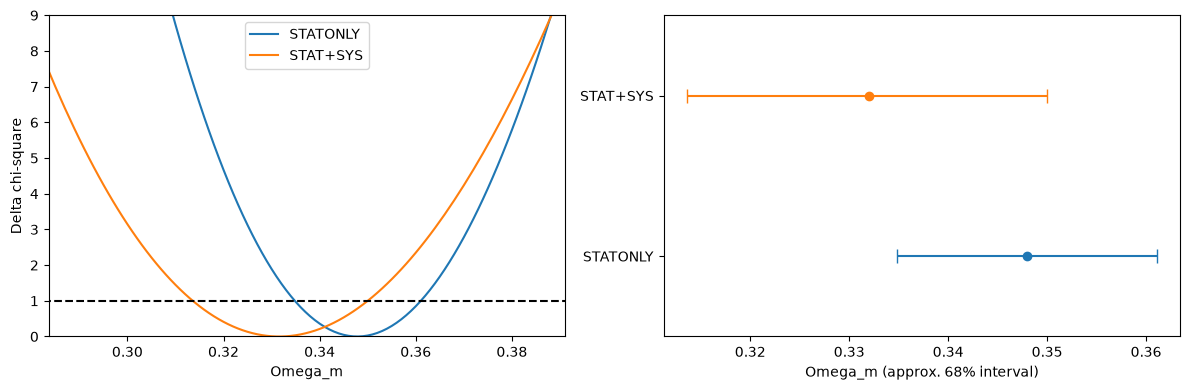

In [6]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(omega_m, dchi2, label="STATONLY")
plt.plot(omega_m, total_profile["delta_chi2"], label="STAT+SYS")
plt.plot([omega_m[0], omega_m[-1]], [1, 1], "k--")
plt.axis([
    min(systematics["lower_68"]) - 0.03,
    max(systematics["upper_68"]) + 0.03,
    0, 9,
])
plt.xlabel("Omega_m")
plt.ylabel("Delta chi-square")
plt.legend()

plt.subplot(1, 2, 2)

for i in range(len(systematics)):
    row = systematics.iloc[i]

    plt.errorbar(
        row["Omega_m"],
        i,
        xerr=[[row["error_minus"]], [row["error_plus"]]],
        fmt="o",
        capsize=5,
    )

plt.yticks([0, 1], systematics["covariance"])
plt.ylim(-0.5, 1.5)
plt.xlabel("Omega_m (approx. 68% interval)")

plt.tight_layout()
plt.savefig("results/sn_systematics_comparison.png", dpi=200)
plt.show()